Import the libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


Load the dataset

In [2]:
# Load the Iris dataset
iris = load_iris(as_frame=True)

# Create the DataFrame
df = iris.frame.copy()

# Display the first five rows
print("First five rows:")
display(df.head())

# Dataset information
print("\nDataset information:")
print(df.info())

# Dataset dimensions
print("\nDataset shape:", df.shape)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Display flower species
print("\nFlower species:")
print(iris.target_names)

First five rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB
None

Dataset shape: (150, 5)

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

Flower species:
['setosa' 'versicolor' 'virginica']


Explore and visualize the data

Statistical description:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


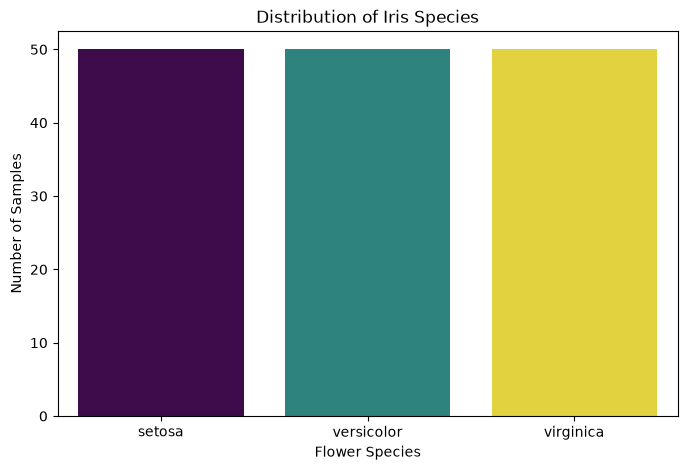

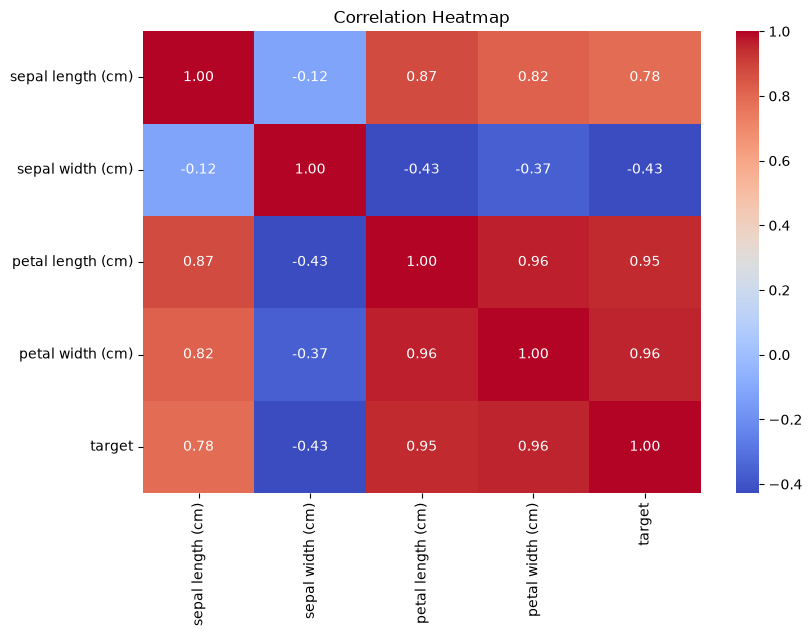

In [3]:
# Statistical description
print("Statistical description:")
display(df.describe())

# Distribution of flower species
plt.figure(figsize=(8, 5))

sns.countplot(
    x="target",
    data=df,
    hue="target",
    palette="viridis",
    legend=False
)

plt.xticks(
    ticks=[0, 1, 2],
    labels=iris.target_names
)

plt.title("Distribution of Iris Species")
plt.xlabel("Flower Species")
plt.ylabel("Number of Samples")
plt.show()


# Correlation heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

Prepare the data

In [4]:
# Separate features and target

X = df.drop(columns=["target"])
y = df["target"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nData preparation completed!")

Training samples: 120
Testing samples: 30

Data preparation completed!


Train the two machine learning models

In [5]:
# MODEL 1: LOGISTIC REGRESSION

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_test)


# MODEL 2: DECISION TREE

decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

decision_tree_model.fit(X_train, y_train)

decision_tree_predictions = decision_tree_model.predict(X_test)

print("Both models trained successfully!")

Both models trained successfully!


Evaluate and compare the models

In [6]:
# Evaluation function

def evaluate_model(name, y_true, predictions):

    accuracy = accuracy_score(y_true, predictions)

    precision = precision_score(
        y_true,
        predictions,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        predictions,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        predictions,
        average="weighted",
        zero_division=0
    )

    print("\n==============================")
    print(name)
    print("==============================")

    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-Score:  {f1:.4f}")

    print("\nClassification Report:")

    print(
        classification_report(
            y_true,
            predictions,
            target_names=iris.target_names
        )
    )

    return {
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    }


# Evaluate both models

results = []

results.append(
    evaluate_model(
        "Logistic Regression",
        y_test,
        logistic_predictions
    )
)

results.append(
    evaluate_model(
        "Decision Tree",
        y_test,
        decision_tree_predictions
    )
)


# Display comparison table

results_df = pd.DataFrame(results)

print("\nFINAL MODEL COMPARISON:")

display(results_df.round(4))


Logistic Regression
Accuracy:  0.9333
Precision: 0.9333
Recall:    0.9333
F1-Score:  0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Decision Tree
Accuracy:  0.9333
Precision: 0.9333
Recall:    0.9333
F1-Score:  0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


FINAL MOD

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333


Confusion matrices

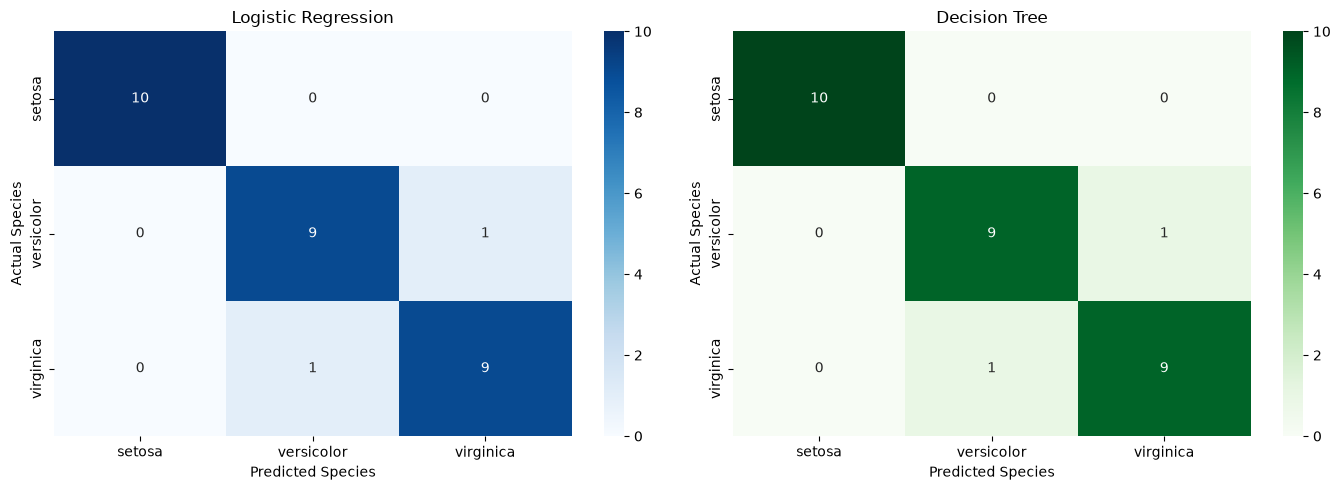

In [7]:
# Confusion matrix for Logistic Regression

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm_logistic = confusion_matrix(
    y_test,
    logistic_predictions
)

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names,
    ax=axes[0]
)

axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted Species")
axes[0].set_ylabel("Actual Species")


# Confusion matrix for Decision Tree

cm_tree = confusion_matrix(
    y_test,
    decision_tree_predictions
)

sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names,
    ax=axes[1]
)

axes[1].set_title("Decision Tree")
axes[1].set_xlabel("Predicted Species")
axes[1].set_ylabel("Actual Species")

plt.tight_layout()
plt.show()

Test your own flower

In [8]:
# Example flower measurements:
# Sepal length, Sepal width, Petal length, Petal width

new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X.columns
)

# Predict using Logistic Regression

prediction = logistic_model.predict(new_flower)

predicted_species = iris.target_names[prediction[0]]

print("New flower measurements:")
display(new_flower)

print("Predicted flower species:", predicted_species)

New flower measurements:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2


Predicted flower species: setosa


Final conclusion

In [9]:
# Identify the best model based on accuracy

best_model = results_df.loc[
    results_df["Accuracy"].idxmax()
]

print("FINAL CONCLUSION")
print("==============================")

print("Best model:", best_model["Model"])

print(
    "Best accuracy:",
    round(best_model["Accuracy"] * 100, 2),
    "%"
)

print("\nBoth models were trained and evaluated successfully.")

print(
    "The comparison shows how different classification "
    "algorithms can solve the same prediction problem."
)

FINAL CONCLUSION
Best model: Logistic Regression
Best accuracy: 93.33 %

Both models were trained and evaluated successfully.
The comparison shows how different classification algorithms can solve the same prediction problem.
